# Import Libraries

In [ ]:
!pip install torchvision
!pip install grad-cam

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.transforms.functional import to_pil_image
import matplotlib.pyplot as plt
from matplotlib import colormaps
import numpy as np
import PIL

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device: {}".format(device))

Device: cpu


# MNIST dataset

MNIST dataset is a database of handwritten digits. It contains a training set of 60,000 examples, and a test set of 10,000 examples. Available here: https://yann.lecun.com/exdb/mnist/

In [3]:
# Define necessary transformations for the datasets
transform = transforms.Compose([
    transforms.ToTensor(),                      # Converts the images to PyTorch tensors
    transforms.Normalize((0.1307,), (0.3081,))  # Normalizes the images with mean and standard deviation for the MNIST dataset
])

In [4]:
# Download and load the training and test datasets
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

Failed to download (trying next):
<urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: certificate has expired (_ssl.c:997)>



100%|████████████████████████████████████████| 9.91M/9.91M [00:05<00:00, 1.67MB/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
<urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: certificate has expired (_ssl.c:997)>



100%|█████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 226kB/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
<urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: certificate has expired (_ssl.c:997)>



100%|█████████████████████████████████████████| 1.65M/1.65M [00:02<00:00, 556kB/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
<urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: certificate has expired (_ssl.c:997)>



100%|████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 3.12MB/s]

Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



In [5]:
# DataLoader wraps the dataset and provides an iterable over the dataset with specified batch size
train_loader = DataLoader(train_dataset, batch_size = 128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size = 128, shuffle=False)

# CNN Model: definition and training

In [6]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(7 * 7 * 64, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

## Training of the model

In [7]:
# Initialize the model
model = SimpleCNN()

In [8]:
# Define loss function, and optimizer
criterion = nn.CrossEntropyLoss()  # Cross-entropy loss for classification tasks
optimizer = optim.Adam(model.parameters(), lr = 0.001)  # Adam optimizer with learning rate 0.001

In [9]:
# Training loop
for epoch in range(5): # Enough for the example
    model.train()
    loss_meter = 0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        loss_meter += loss.item()

    print(f'Epoch {epoch + 1}, Loss: {loss_meter / len(train_loader)}')

Epoch 1, Loss: 0.17024319020828713
Epoch 2, Loss: 0.04671587718368721
Epoch 3, Loss: 0.032967981492191045
Epoch 4, Loss: 0.02502737802526316
Epoch 5, Loss: 0.018122427899371595


# Implement GradCAM class

The GradCAM class is composed of several compontents useful to compute the activation map.

Here a brief explanation of them:
- The attributes of the class are:
  - `model` is the trained CNN model.
  - `target_layer` is the specific layer in the model from which to extract the feature maps (usually the last convolutional layer).

  - Hooks are specific functions that process information that flows through the model during the forward or backward pass. They return a `torch.utils.hooks.RemovableHandle`. In particular, `register_forward_hook` and `register_full_backward_hook` register the forward and backward hook on the module, i.e., the hook function runs when the `forward()` and the `backward()` methods are called.
- `forward_hook` captures the output (activations) of the target layer during the forward pass of the model, which correspond to the features that the CNN has identified as important in the input image.
- `backward_hook` captures the gradients of the loss with respect to the activations of the target layer during the backward pass. These gradients represent how much each activation contributed to the final decision for the specific class of interest.
- `generate_cam` generates the map which highlights the regions in the input image that most influenced the model's decision. The steps of the funtions are:
  - forward pass and class selection: pass the image in the model and obtain the output;
  - backward pass: calculate the gradients of the obtained class w.r.t. the activations in the target layer;
  - weight the activations in order to highlight the features that are most important for the decision of the selected class;
  - combine the weighted features to generate a 2D map, which can be represented as an heatmap;
  - pass the heatmap through a ReLU function to retain only positive values (since we are interested in features that positively contribute to the class), and then normalized to a range between 0 and 1.

In [10]:
class custom_GradCAM:
    def __init__(self, model, target_layer):
        self.model = model.eval()
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register hooks to capture forward and backward pass data
        self.target_layer.register_forward_hook(self.forward_hook)
        self.target_layer.register_full_backward_hook(self.backward_hook)

    def backward_hook(self, module, grad_input, grad_output):
        # Hook to capture the gradients after the backward pass
        self.gradients = grad_output[0].detach()

    def forward_hook(self, module, input, output):
        # Hook to capture the activations after the forward pass
        self.activations = output.detach()

    def generate_cam(self, input_image, target_class=None):
        # Generate the CAM
        model_output = self.model(input_image)  # Forward pass
        if target_class is None:
            target_class = model_output.argmax(dim=1).item()  # Use the predicted class if none specified

        # Backpropagate to get gradients w.r.t. the target class
        self.model.zero_grad()  # Zero the gradients
        class_loss = model_output[:, target_class]  # Get the output score for the target class
        class_loss.backward(retain_graph=True)  # Backward pass

        # Generate CAM by weighting the activations by the gradients
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])  # Global average pooling over the gradients
        for i in range(self.activations.shape[1]):
            self.activations[:, i, :, :] *= pooled_gradients[i]  # Weight each activation map

        cam = torch.mean(self.activations, dim=1).squeeze().cpu().numpy()  # Average the weighted activations to get the heatmap
        cam = np.maximum(cam, 0)  # Apply ReLU to the heatmap
        cam = (cam - cam.min()) / (cam.max() - cam.min())  # Normalize the heatmap to [0, 1]

        return cam


## Visualization

`visualization` function applies the selected `cam` on a sample provided as input of the function. The resulting heatmap is resized and overlayed to the input image.

In [11]:
def visualization(model, target_layer, image, label, cam):

    model.eval()

    input_image = image.unsqueeze(0)  # Add batch dimension

    # Convert the image tensor to a NumPy array for visualization
    image_np = input_image.squeeze().numpy()

    # Plot the original image and CAM heatmap
    plt.figure(figsize=(10, 5))

    # Original image (grayscale)
    plt.subplot(1, 2, 1)
    plt.imshow(image_np, cmap='gray')
    plt.title(f'Original Image - Label: {label}')
    plt.axis('off')

    # Heatmap
    plt.subplot(1, 2, 2)
    plt.imshow(image_np, cmap='gray')
    # Convert the image tensor to a PIL image and rescale it
    overlay = to_pil_image(cam, mode='F').resize(image_np.shape, resample=PIL.Image.BICUBIC)
    # Obtain the colormap
    cmap = colormaps['jet']
    # Convert the CAM in the heatmap by applying the colormap
    overlay = (255 * cmap(np.asarray(overlay) ** 2)[:, :, :3]).astype(np.uint8)
    # Overlay the heatmap with transparency, alpha varies the transparency
    plt.imshow(overlay, cmap='jet', alpha=0.5)
    plt.title(f'Grad-CAM Heatmap - Output: {model(input_image).max(dim=1)[1].item()}')
    plt.axis('off')

/var/folders/ht/fb0zdj4j52j3qx4rfz6vx_zr0000gn/T/ipykernel_71009/2988765150.py:38: RuntimeWarning: invalid value encountered in divide
  cam = (cam - cam.min()) / (cam.max() - cam.min())  # Normalize the heatmap to [0, 1]


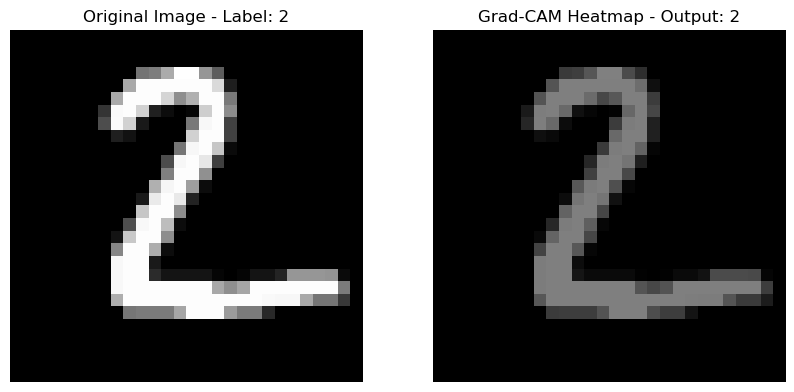

In [12]:
# Take a single sample of the test set
image, label = test_dataset[1]

# Get the model
model = model

# Decide the layer
target_layer = model.conv2

# Initialize GradCAM with the target layer
grad_cam = custom_GradCAM(model, target_layer)

# Generate the CAM for the selected image
cam = grad_cam.generate_cam(image.unsqueeze(0))

# Visualize the CAM as a heatmap
visualization(model, target_layer, image, label, cam)

# Explore GradCAM library



After learning about `GradCAM`, we can explore one of the best available online libraries provided by Jacob Gildenblat (https://github.com/jacobgil/pytorch-grad-cam/tree/master). This library offers numerous modifications and improvements to the basic technique we just introduced, allowing us to obtain more accurate and precise explanations.

In [14]:
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

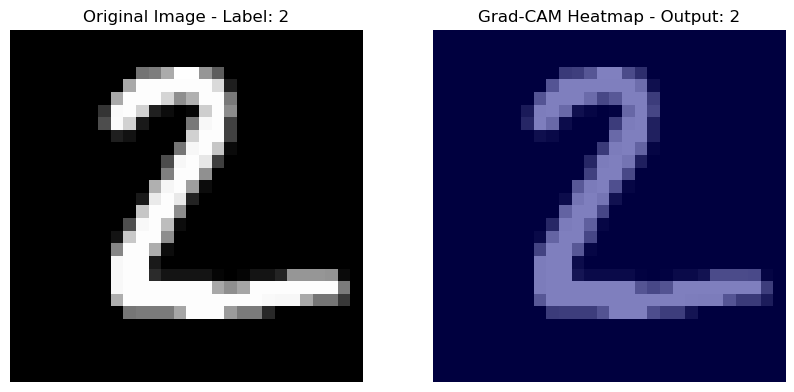

In [23]:
# Take a single sample of the test set
image, label = test_dataset[1]

# Get the model
model = model

# Decide the layer
target_layer = model.conv2

# Initialize GradCAM with the target layer
grad_cam = GradCAM(model=model, target_layers=[target_layer])

# Generate the CAM for the selected image including as target the predicted label
cam = grad_cam(input_tensor = image.unsqueeze(0), targets = [ClassifierOutputTarget(model(image.unsqueeze(0)).max(dim=1)[1].item())])[0, :]

# Visualize the CAM as a heatmap
visualization(model, target_layer, image, label, cam)

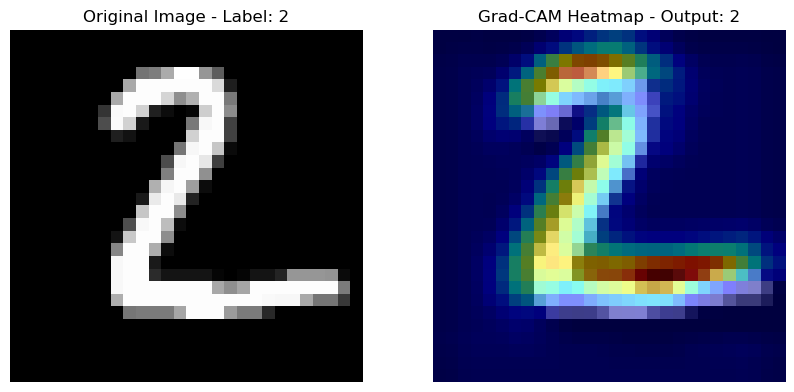

In [16]:
# Take a single sample of the test set
image, label = test_dataset[1]

# Get the model
model = model

# Decide the layer
target_layer = model.conv2

# Initialize GradCAM with the target layer
grad_cam_plusplus = GradCAMPlusPlus(model=model, target_layers=[target_layer])

# Generate the CAM for the selected image including as target the predicted label
cam = grad_cam_plusplus(input_tensor = image.unsqueeze(0), targets = [ClassifierOutputTarget(model(image.unsqueeze(0)).max(dim=1)[1].item())])[0, :]

# Visualize the CAM as a heatmap
visualization(model, target_layer, image, label, cam)

## Guided-backpropagation

Guided-backpropagation is simple and available in GradCAM library.

In [17]:
import cv2
from pytorch_grad_cam import GuidedBackpropReLUModel
from pytorch_grad_cam.utils.image import deprocess_image

In [18]:
# Take a single sample of the test set
image, label = test_dataset[1]

# Get the model
model = model

In [19]:
# Decide the layer
target_layer = model.conv2

# Initialize GradCAM with the target layer
grad_cam = GradCAM(model=model, target_layers=[target_layer])

# Generate the CAM for the selected image including as target the predicted label
cam = grad_cam(input_tensor = image.unsqueeze(0), targets = [ClassifierOutputTarget(model(image.unsqueeze(0)).max(dim=1)[1].item())])[0, :]

# Create a 3D version of the CAM
cam_mask = cv2.merge([cam, cam, cam])

# Obtain the Guided-backpropagation model from the trained model
gb_model = GuidedBackpropReLUModel(model=model, device=device)

# Generate the Guidid-backropagation map for the selected image including as target the predicted label
gb = gb_model(image.unsqueeze(0), target_category=None)

# Multiplicate the two maps to obtain the visualization of the Guided-backpropagation map
cam_gb = deprocess_image(cam_mask * gb)

(-0.5, 27.5, 27.5, -0.5)

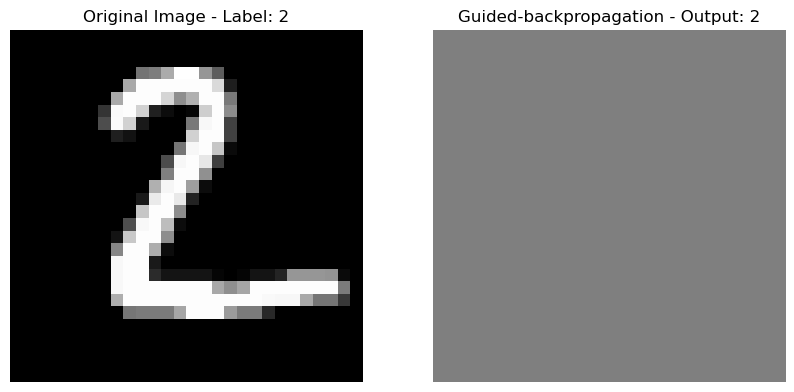

In [20]:
input_image = image.unsqueeze(0)  # Add batch dimension

# Convert the image tensor to a NumPy array for visualization
image_np = input_image.squeeze().numpy()

# Plot the original image and CAM heatmap
plt.figure(figsize=(10, 5))

# Original image (grayscale)
plt.subplot(1, 2, 1)
plt.imshow(image_np, cmap='gray')
plt.title(f'Original Image - Label: {label}')
plt.axis('off')

# Heatmap
plt.subplot(1, 2, 2)
plt.imshow(cam_gb)
plt.title(f'Guided-backpropagation - Output: {model(input_image).max(dim=1)[1].item()}')
plt.axis('off')

# Conclusion

We have explained the definition of the GradCAM class and its basic functions. Additionally, we have presented an example of the widely used and established GradCAM library, which is considered state-of-the-art. The techniques demonstrated are fundamental, and there are numerous variations that can be explored.

